# Fase 3 — Entrenamiento, comparación y registro de modelos
El entrenamiento real lo hace `src/train_model.py` (es lo que se versiona y se puede re-ejecutar). Este notebook **lee sus
artefactos** (`results/experiment_logs.csv`, `results/predicciones_*.csv`, `models/model_registry.json`) y los analiza.
Antes de abrirlo: `python src/preprocessing_pipeline.py && python src/train_model.py`.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import auxiliar_functions as af
import train_model as tm
SEMILLA = af.SEMILLA
pd.set_option("display.width", 200); sns.set_theme(style="whitegrid"); FIG = af.FIG_DIR
ds = pd.read_csv(ROOT / "data/processed/dataset_final.csv", index_col="fecha", parse_dates=True)
feats = json.loads((ROOT / "data/processed/selected_features.json").read_text())["seleccionadas"]
registry = json.loads((ROOT / "models/model_registry.json").read_text())
entry = registry[max(registry, key=lambda v: tuple(map(int, v.split("."))))]
logs = pd.read_csv(ROOT / "results/experiment_logs.csv")
tr, va, te = (ds[ds.split == s] for s in ("train", "val", "test"))
print(f"train {tr.shape[0]} | val {va.shape[0]} | test {te.shape[0]} días | {len(feats)} features")

train 815 | val 174 | test 175 días | 11 features


## 3.1 Baselines obligatorios
Implementados en pocas líneas de pandas, sobre **las mismas filas y el mismo preprocesamiento** que el modelo:
- **Persistencia:** ŷ[D+1] = y[D] → la columna `frio_hoy` (Frio del día D a las 23:59).
- **Media móvil 7 días:** ŷ[D+1] = promedio de D-6…D → la columna `frio_rm7`.

In [2]:
def baselines(df):
    return pd.DataFrame({"persistencia": df["frio_hoy"], "media_movil_7d": df["frio_rm7"]})
# comprobación: frio_rm7 es exactamente la media de los 7 días previos cuando no faltan días
u = pd.read_csv(ROOT / "data/interim/dataset_unificado.csv", index_col=0, parse_dates=True)[af.TARGET]
chk = u.rolling(7).mean().reindex(va.index).dropna()
print("max |frio_rm7 - rolling(7).mean()| en validación:", float((va.loc[chk.index, "frio_rm7"] - chk).abs().max()))
{k: round(mean_absolute_error(va.y, p), 1) for k, p in baselines(va).items()}

max |frio_rm7 - rolling(7).mean()| en validación: 4.2857209336943924e-07


{'persistencia': 2701.8, 'media_movil_7d': 2570.8}

## 3.2 Espacio de búsqueda y tracking de experimentos
Cada configuración se ajusta en **train** y se evalúa en **validación**; cada ejecución agrega una fila a
`results/experiment_logs.csv` con timestamp, hiperparámetros, MAE, RMSE y R². Cada configuración se prueba de dos formas:
prediciendo el **nivel** y prediciendo el **cambio** respecto de hoy (`DeltaRegressor`: ŷ = frio_hoy + f(X)), que les da a
los árboles una forma de no tener que extrapolar niveles.

In [3]:
pd.DataFrame([{"modelo": k, "grilla": {p: v for p, v in g.items() if p not in ("random_state", "n_jobs", "verbose")},
               "n_configs": int(np.prod([len(v) for v in g.values()])) * len(tm.OBJETIVOS)}
              for k, (_, g) in tm.SEARCH_SPACE.items()])

,modelo,grilla,n_configs
0,Ridge,"{'alpha': [0.1, 1, 3, 10, 30, 100]}",12
1,Lasso,"{'alpha': [1, 10, 30, 100, 300], 'max_iter': [...",10
2,RandomForest,"{'n_estimators': [400], 'max_depth': [None, 8]...",16
3,XGBoost,"{'n_estimators': [300, 600], 'learning_rate': ...",8
4,LightGBM,"{'n_estimators': [300, 600], 'learning_rate': ...",8


In [4]:
print(f"Filas en el log: {len(logs)} | ejecuciones (run_id): {logs.run_id.nunique()}")
ultimo = logs[(logs.run_id == logs.run_id.max()) & (logs.split_eval == "val")]
mejor = ultimo.sort_values("MAE").groupby(["modelo"], as_index=False).first().sort_values("MAE")
mejor[["modelo", "objetivo", "params", "MAE", "RMSE", "R2", "fit_seconds"]].round(3)

Filas en el log: 59 | ejecuciones (run_id): 1


,modelo,objetivo,params,MAE,RMSE,R2,fit_seconds
0,Lasso,nivel,"{""alpha"": 300, ""max_iter"": 50000}",2103.276,2808.960,0.513,0.004
2,RandomForest,nivel,"{""n_estimators"": 400, ""max_depth"": 8, ""min_sam...",2103.834,2837.621,0.503,0.451
3,Ridge,nivel,"{""alpha"": 100}",2112.000,2849.046,0.499,0.004
4,XGBoost,nivel,"{""n_estimators"": 300, ""learning_rate"": 0.03, ""...",2191.556,2913.112,0.476,0.163
1,LightGBM,nivel,"{""n_estimators"": 300, ""learning_rate"": 0.03, ""...",2225.373,2944.973,0.464,0.194
5,media_movil_7d,-,{},2570.798,3425.020,0.276,0.000
6,persistencia,-,{},2701.845,3339.610,0.311,0.000


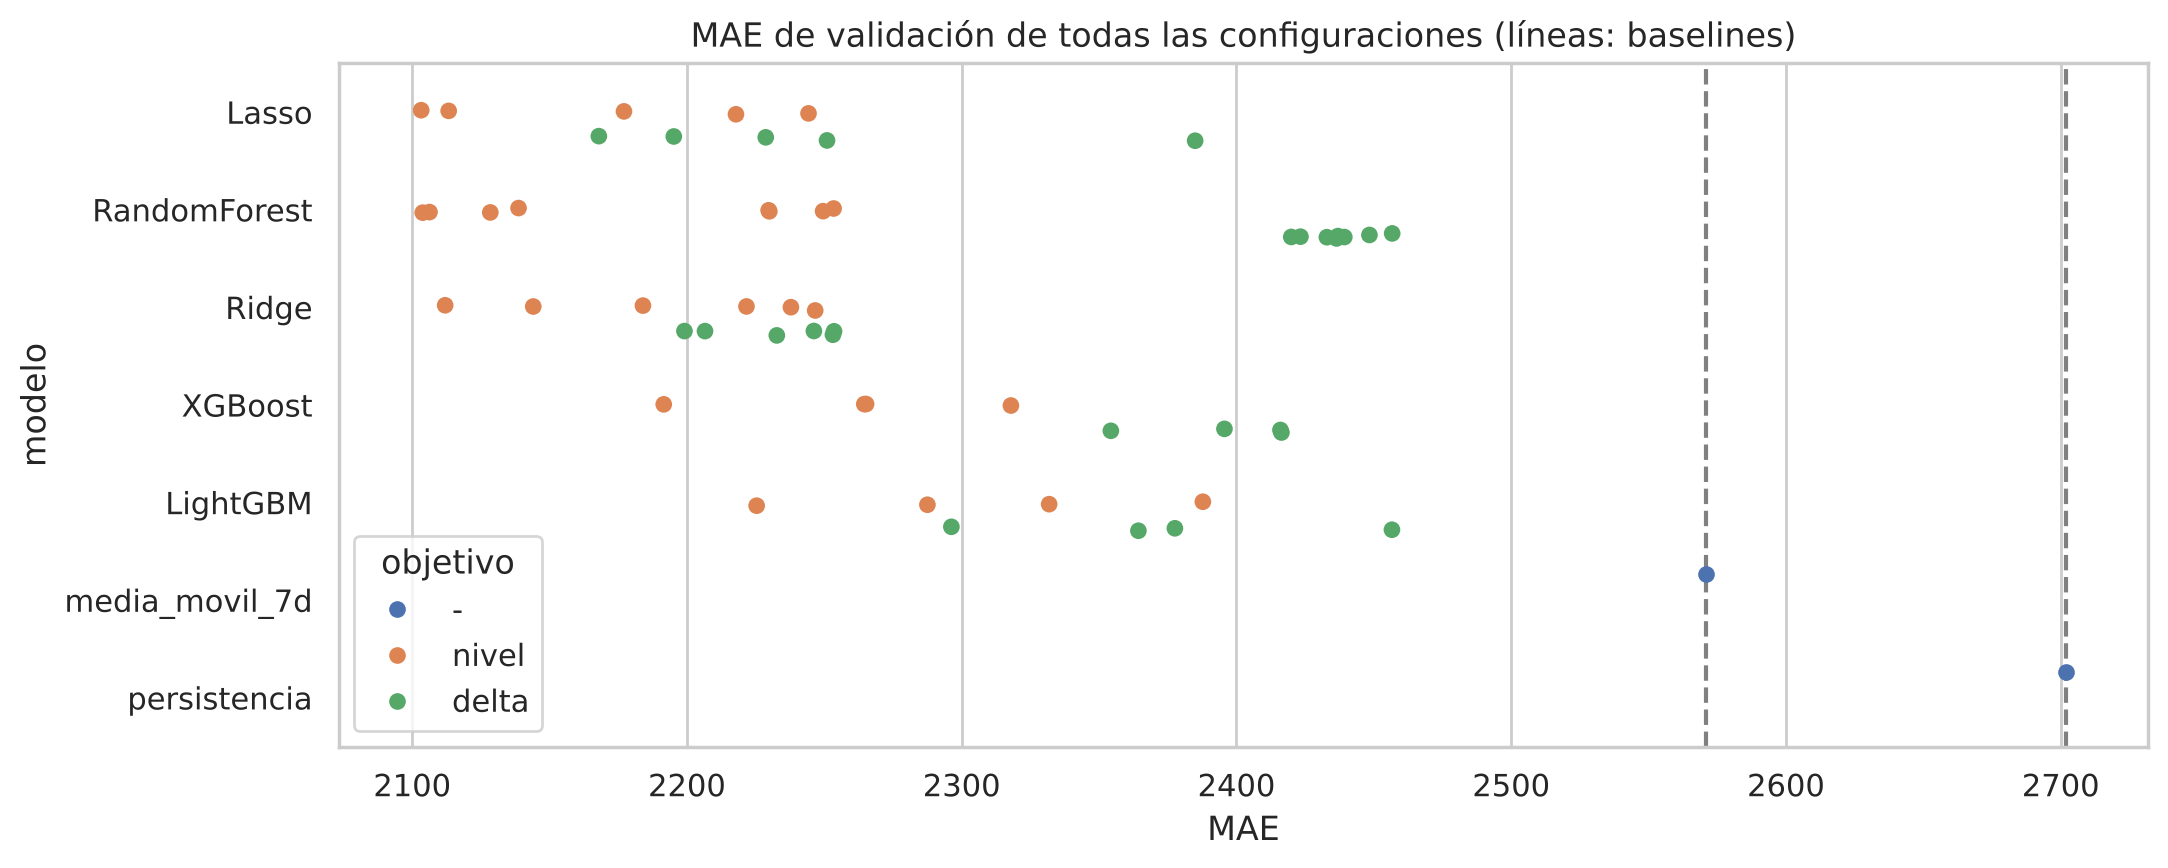

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.5))
v = ultimo.copy(); v["config"] = v.modelo + " / " + v.objetivo
sns.stripplot(data=v, y="modelo", x="MAE", hue="objetivo", dodge=True, size=6, ax=ax,
              order=mejor.modelo.tolist())
for b in ("persistencia", "media_movil_7d"):
    ax.axvline(ultimo.loc[ultimo.modelo == b, "MAE"].iloc[0], ls="--", c="gray")
ax.set_title("MAE de validación de todas las configuraciones (líneas: baselines)")
plt.tight_layout(); plt.savefig(FIG / "comparacion_modelos_val.png", dpi=120); plt.show()

**Elección del mejor modelo (solo con validación).** Los modelos lineales regularizados (Lasso/Ridge) ganan con margen a los de
árboles. Es lo esperable con ~800 días de entrenamiento y una relación casi lineal con el nivel reciente: los árboles parten el
espacio en escalones y no pueden predecir valores fuera del rango visto en train, mientras que un modelo lineal sigue
la tendencia del nivel reciente. Predecir el *cambio* (objetivo `delta`) ayuda a los árboles, pero no alcanza. Entre Lasso y Ridge la diferencia es
de pocos kW; se elige el de menor MAE de validación (el modelo y sus hiperparámetros están en el registro, al final).

## 3.3 Evaluación en validación del modelo elegido (entrenado solo con train)

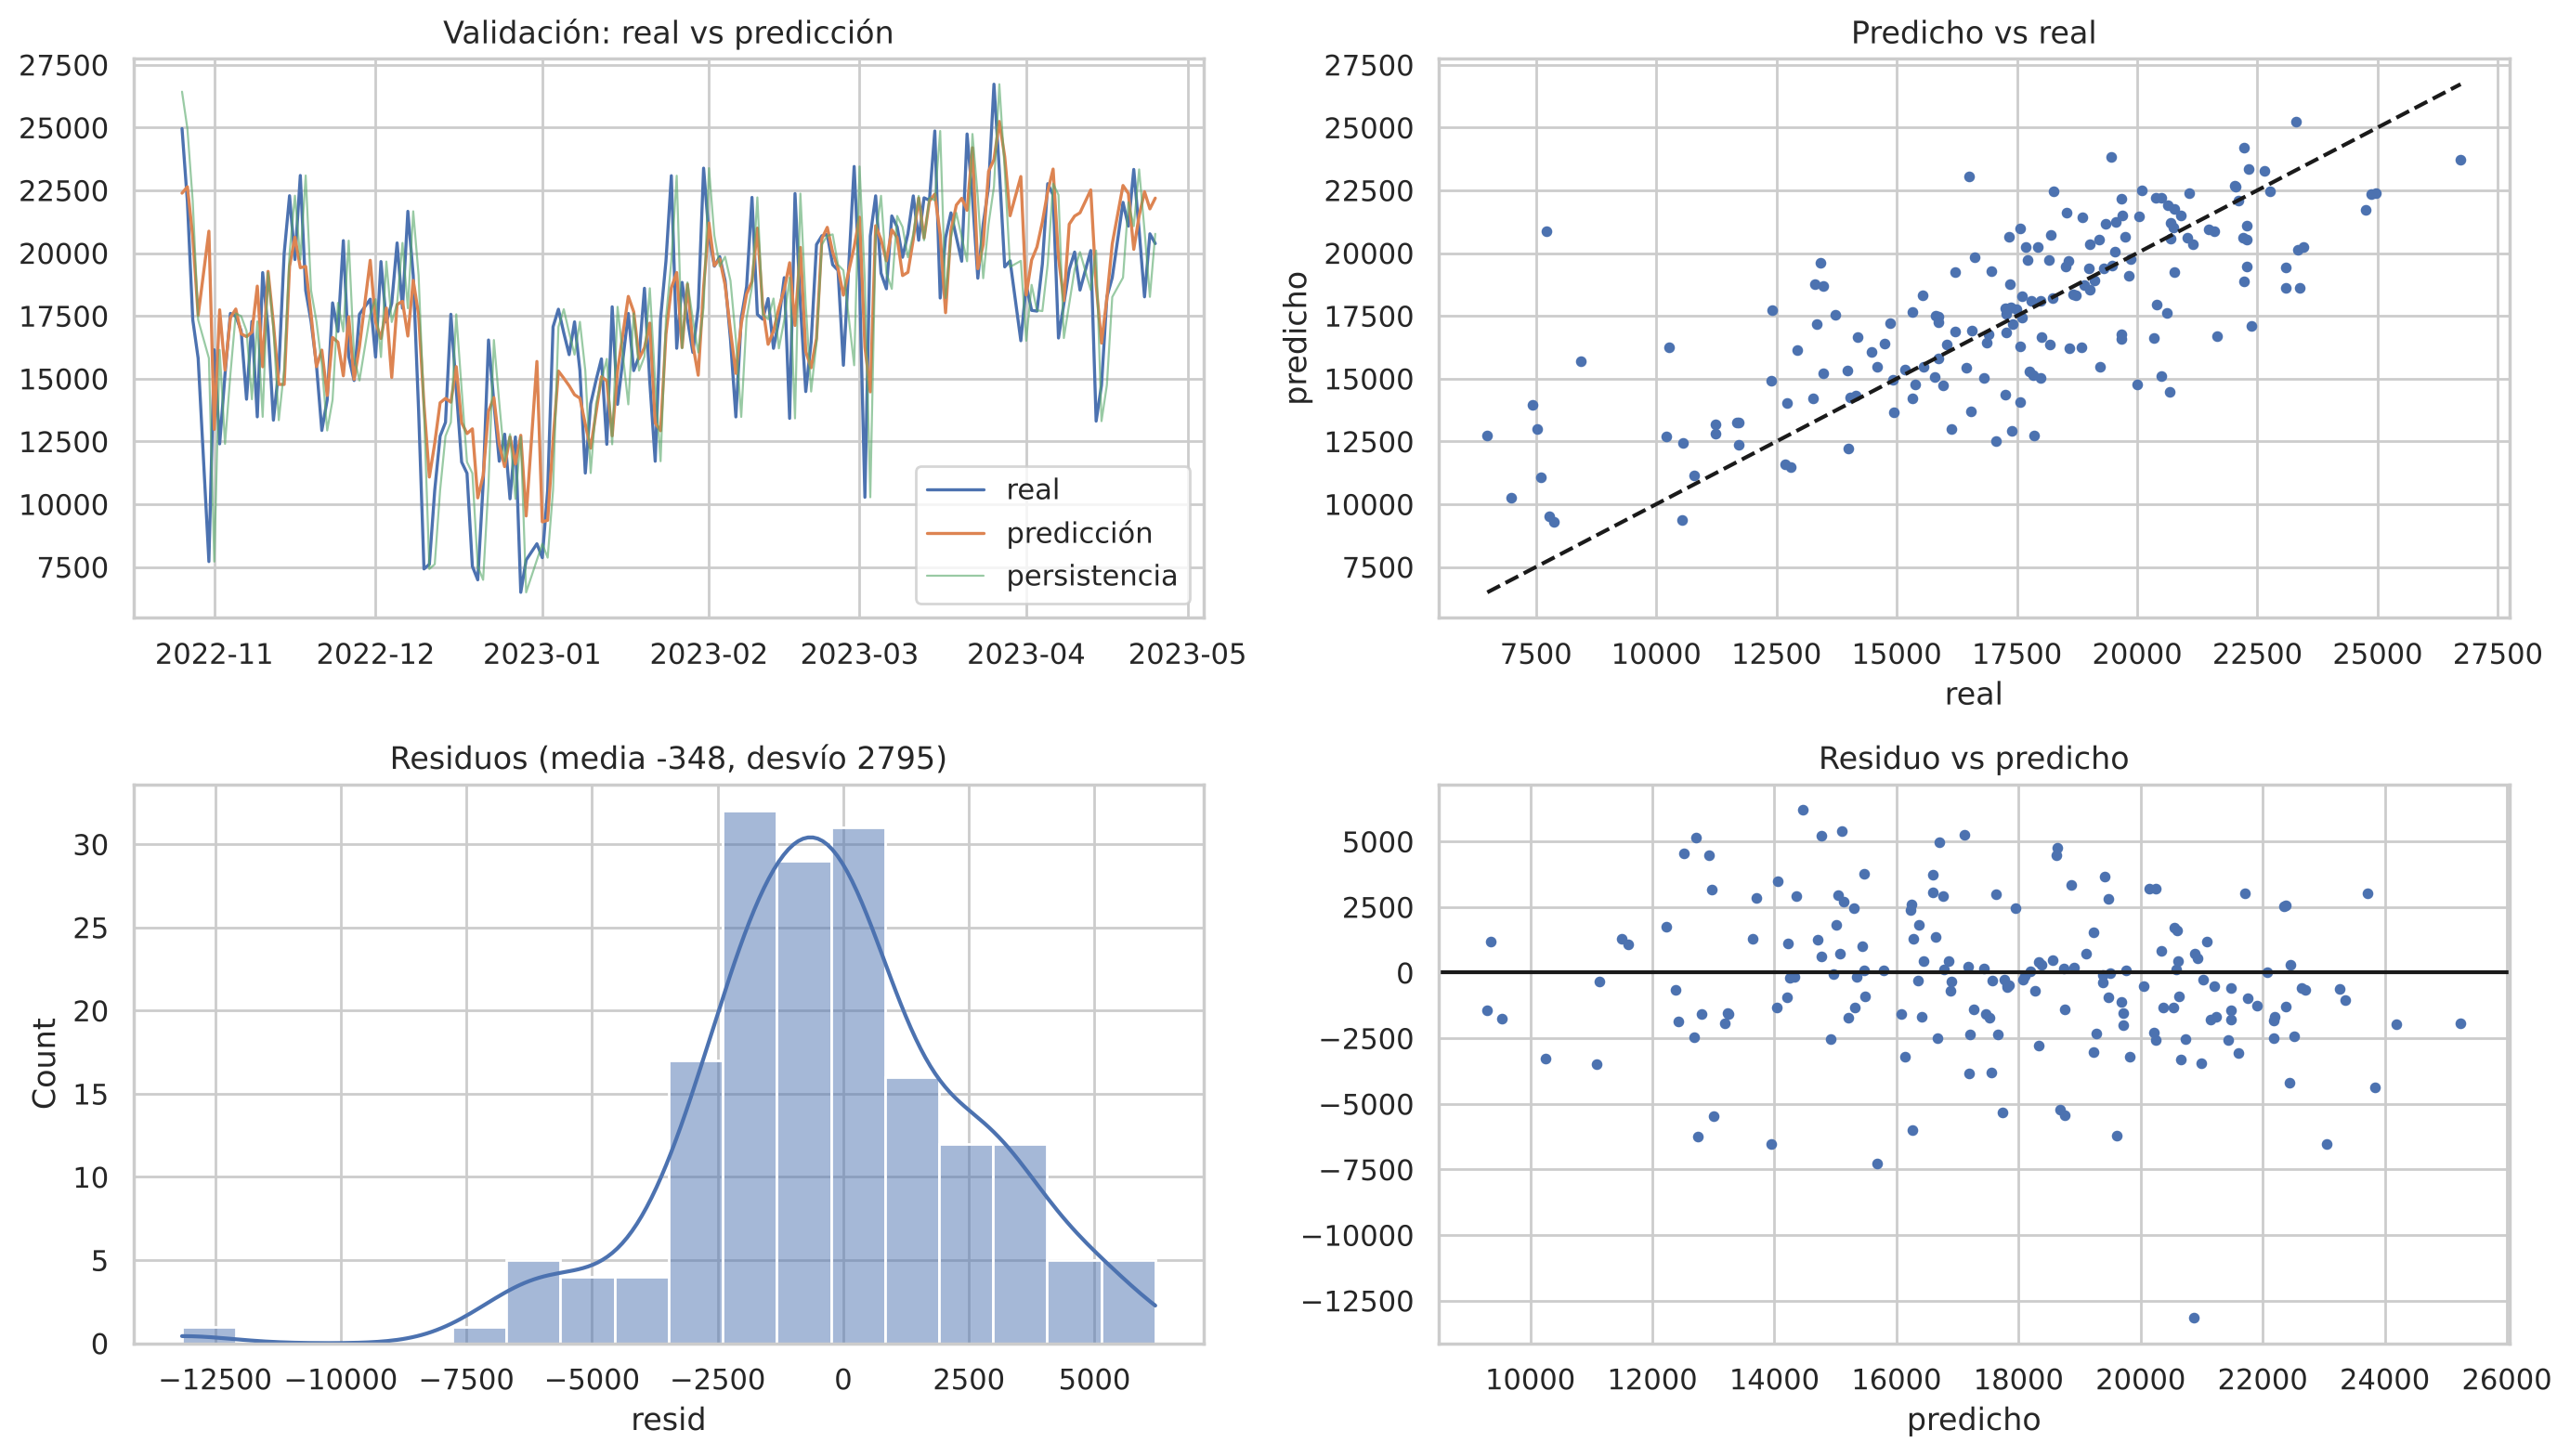

Autocorrelación lag-1 de los residuos: -0.001
MAE por mes en validación:
fecha
2022-10    4269.0
2022-11    1960.0
2022-12    2477.0
2023-01    2245.0
2023-02    1525.0
2023-03    2124.0
2023-04    1794.0
Freq: M


In [6]:
pv = pd.read_csv(ROOT / "results/predicciones_validacion.csv", parse_dates=["fecha"]).set_index("fecha")
pv["resid"] = pv.y_real - pv.y_pred
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
ax[0, 0].plot(pv.index, pv.y_real, label="real", lw=1.2); ax[0, 0].plot(pv.index, pv.y_pred, label="predicción", lw=1.2)
ax[0, 0].plot(pv.index, pv.persistencia, label="persistencia", lw=.8, alpha=.6); ax[0, 0].legend(); ax[0, 0].set_title("Validación: real vs predicción")
ax[0, 1].scatter(pv.y_real, pv.y_pred, s=10); lim = [pv.y_real.min(), pv.y_real.max()]; ax[0, 1].plot(lim, lim, "k--")
ax[0, 1].set_xlabel("real"); ax[0, 1].set_ylabel("predicho"); ax[0, 1].set_title("Predicho vs real")
sns.histplot(pv.resid, kde=True, ax=ax[1, 0]); ax[1, 0].set_title(f"Residuos (media {pv.resid.mean():.0f}, desvío {pv.resid.std():.0f})")
ax[1, 1].scatter(pv.y_pred, pv.resid, s=10); ax[1, 1].axhline(0, c="k"); ax[1, 1].set_xlabel("predicho"); ax[1, 1].set_title("Residuo vs predicho")
plt.tight_layout(); plt.savefig(FIG / "residuos_validacion.png", dpi=120); plt.show()
print("Autocorrelación lag-1 de los residuos:", round(pv.resid.autocorr(1), 3))
print("MAE por mes en validación:"); print(pv.resid.abs().groupby(pv.index.to_period("M")).mean().round(0).to_string())

Los residuos están centrados y sin forma de embudo marcada. Los errores grandes son días de cambio brusco (arranques y
paradas, cambios de régimen de producción) que nada en el día D anticipa; el peor mes es octubre de 2022, con días de transición
muy por debajo del nivel previo. Los residuos no tienen autocorrelación de lag 1, así que no queda información obvia en la historia
del propio Frio: lo próximo a agregar sería información **del día D+1** conocida de antemano (pronóstico de temperatura, plan de
producción).

## Importancia de variables del mejor modelo
Lasso pone coeficiente **exactamente 0** a parte de las variables seleccionadas: es su propia selección adicional. La tabla muestra
cuáles pesan de verdad.

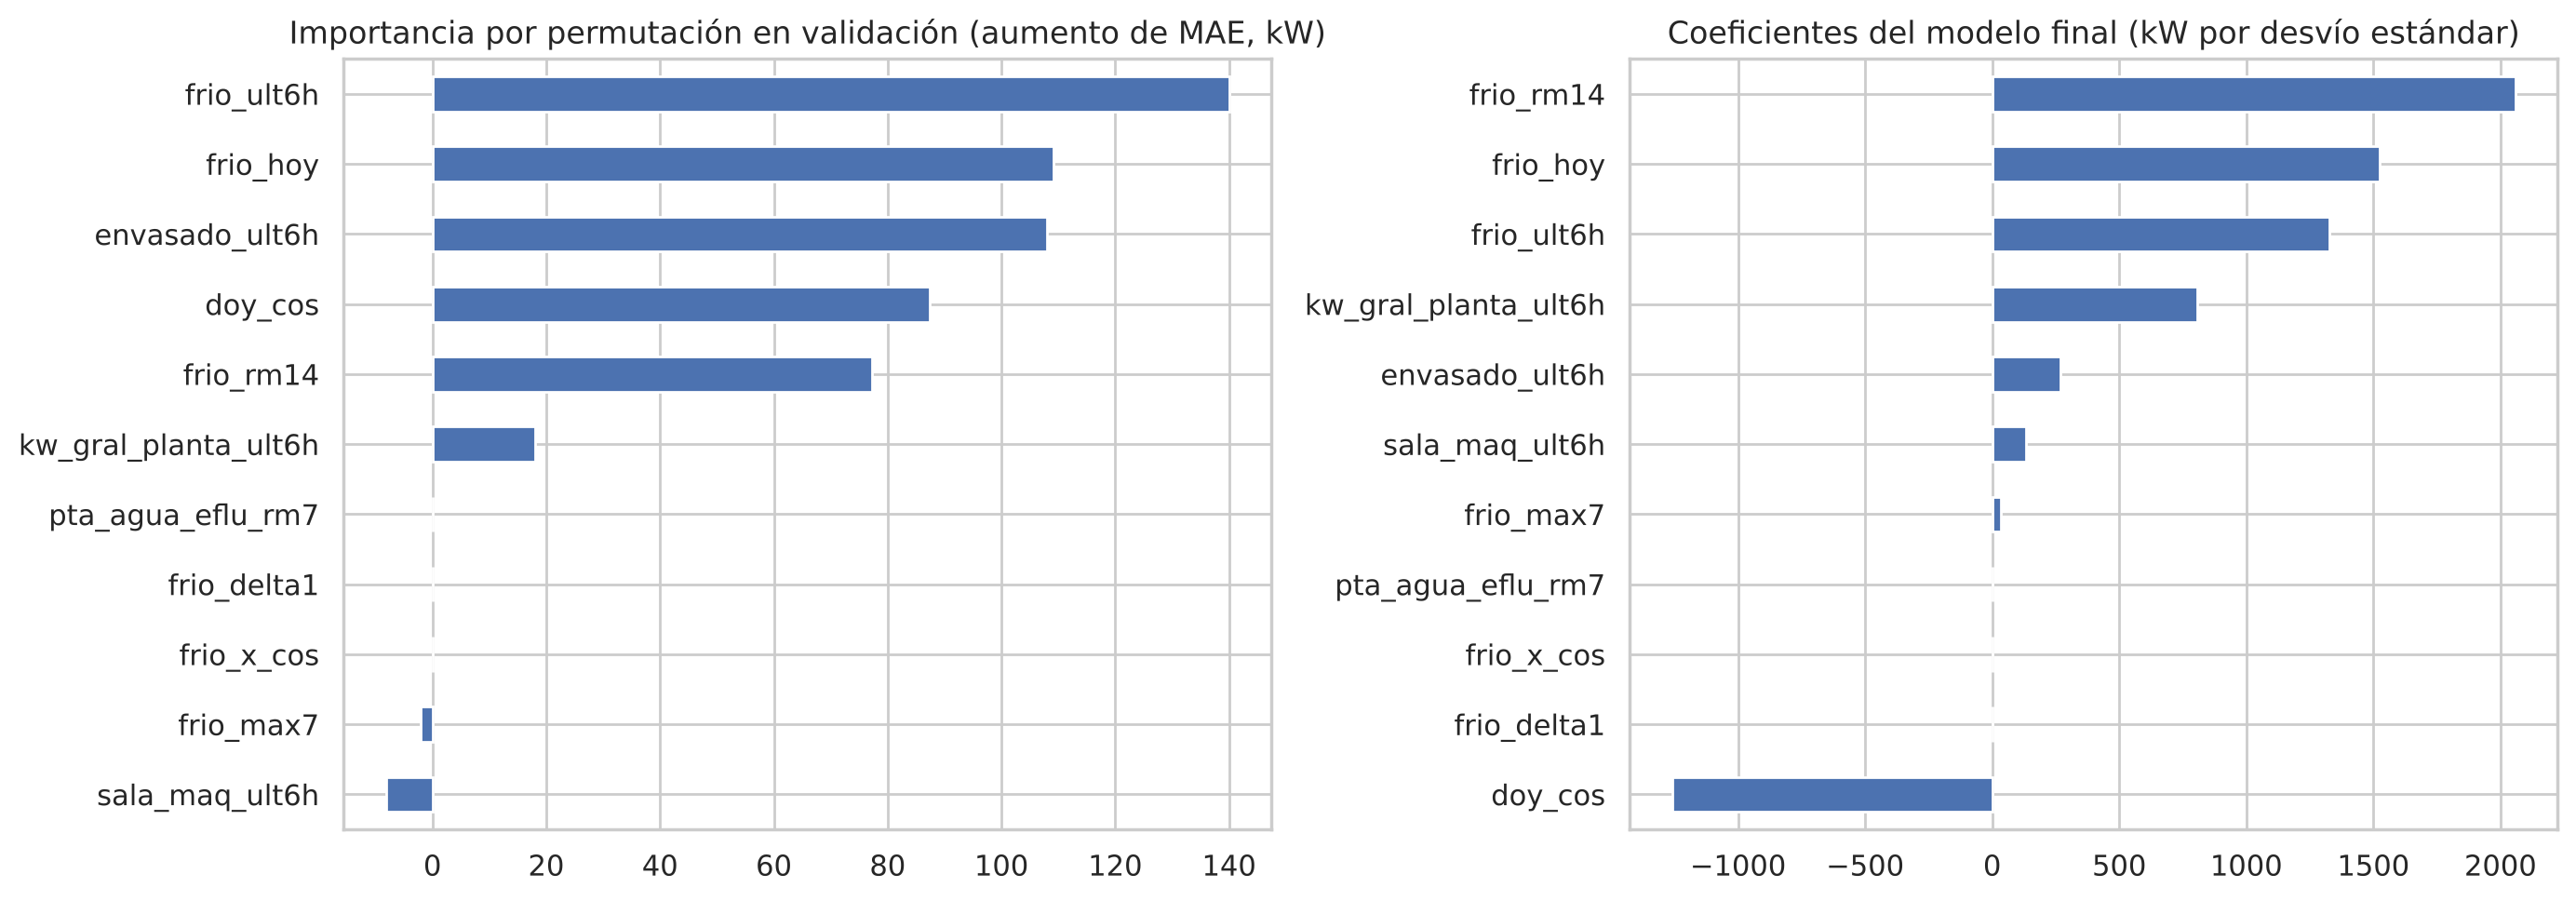

,permutacion_kW,coef_final
frio_ult6h,140.0,1325.3
frio_hoy,109.1,1525.1
envasado_ult6h,108.1,268.2
doy_cos,87.4,-1259.1
frio_rm14,77.2,2058.1
kw_gral_planta_ult6h,18.0,806.4
frio_delta1,0.0,0.0
pta_agua_eflu_rm7,0.0,0.0
frio_x_cos,0.0,-0.0
frio_max7,-2.1,35.1


In [7]:
best_tr = tm.make_model(entry["modelo"], entry["hiperparametros"], entry["objetivo"]).fit(tr[feats], tr.y)
pi = permutation_importance(best_tr, va[feats], va.y, scoring="neg_mean_absolute_error",
                            n_repeats=30, random_state=SEMILLA)
imp = pd.Series(pi.importances_mean, index=feats).sort_values()
final = joblib.load(ROOT / entry["path"])
est = final.estimator_ if hasattr(final, "estimator_") else final
coef = pd.Series(est.named_steps["model"].coef_, index=feats).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
imp.plot.barh(ax=ax[0], title="Importancia por permutación en validación (aumento de MAE, kW)")
coef.plot.barh(ax=ax[1], title="Coeficientes del modelo final (kW por desvío estándar)")
plt.tight_layout(); plt.savefig(FIG / "importancia_variables.png", dpi=120); plt.show()
pd.DataFrame({"permutacion_kW": imp, "coef_final": coef}).sort_values("permutacion_kW", ascending=False).round(1)

## 3.4 Modelo final: reentrenado con train+validación y evaluado UNA vez en test

,MAE,RMSE,R2,mejora_MAE_vs_modelo
modelo_final,2724.060,3571.959,0.604,0.000
persistencia,3356.869,4322.725,0.420,0.189
media_movil_7d,3047.752,3975.920,0.510,0.106


Mejora sobre el mejor baseline: 10.6%


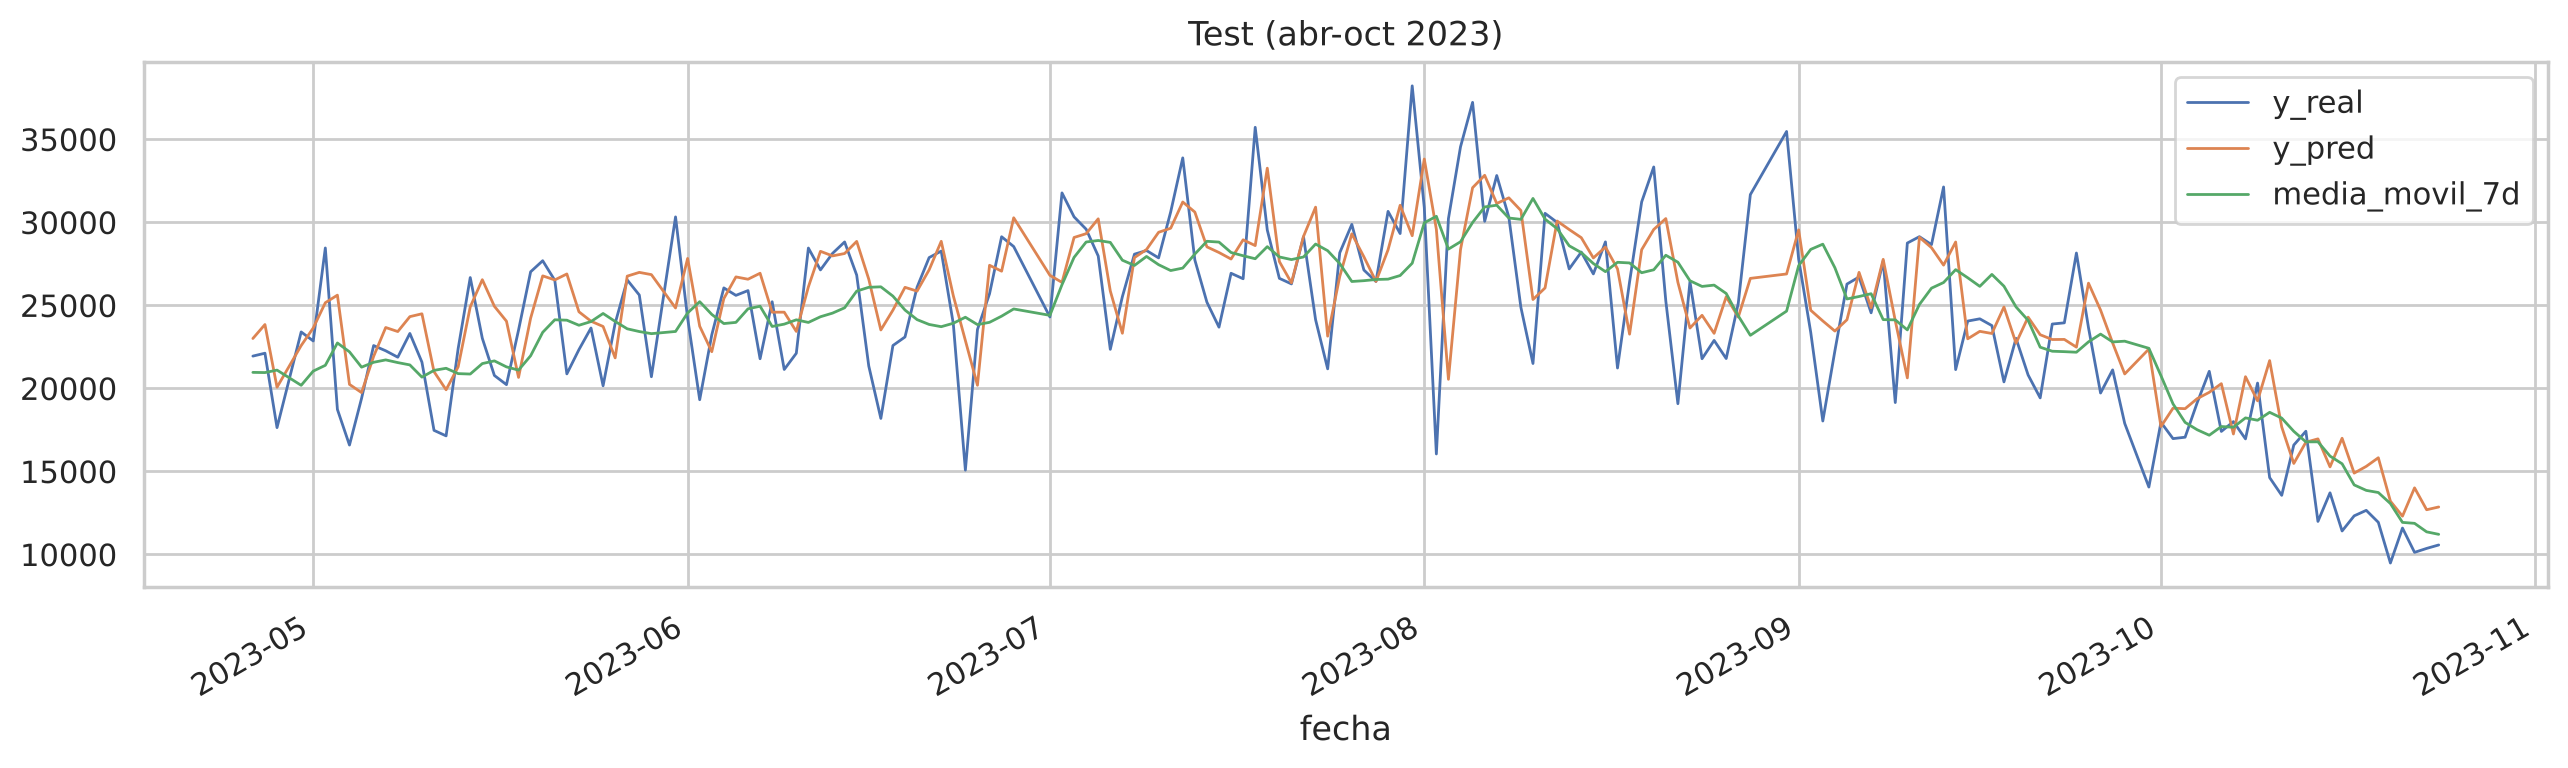

In [8]:
tabla = pd.DataFrame(entry["metricas_test"]).T[["MAE", "RMSE", "R2"]].round(3)
tabla["mejora_MAE_vs_modelo"] = (1 - tabla.loc["modelo_final", "MAE"] / tabla["MAE"]).round(3)
display(tabla)
print(f"Mejora sobre el mejor baseline: {entry['mejora_vs_mejor_baseline_test']:.1%}")
pt = pd.read_csv(ROOT / "results/predicciones_test.csv", parse_dates=["fecha"]).set_index("fecha")
ax = pt[["y_real", "y_pred", "media_movil_7d"]].plot(figsize=(13, 4), lw=1, title="Test (abr-oct 2023)")
plt.tight_layout(); plt.savefig(FIG / "test_real_vs_pred.png", dpi=120); plt.show()

### Umbral de reemplazo de un modelo desplegado (pregunta 4)

In [9]:
folds = np.array(entry["cv_train_mae_folds"])
print("MAE por fold (TimeSeriesSplit sobre train):", folds.round(0), f"-> desvío {folds.std(ddof=1):,.0f} kW")
# Bootstrap por bloques semanales de la diferencia de MAE entre el mejor modelo y el mejor baseline en validación
e_m = (pv.y_real - pv.y_pred).abs().values; e_b = (pv.y_real - pv.media_movil_7d).abs().values
rng = np.random.default_rng(SEMILLA); n = len(e_m); B = 7
difs = []
for _ in range(2000):
    starts = rng.integers(0, n - B, size=n // B)
    idx = np.concatenate([np.arange(s, s + B) for s in starts])
    difs.append(e_b[idx].mean() - e_m[idx].mean())
difs = np.array(difs)
print(f"Diferencia de MAE (baseline - modelo) en validación: {e_b.mean() - e_m.mean():,.0f} kW, "
      f"IC95% bootstrap por bloques [{np.percentile(difs, 2.5):,.0f}; {np.percentile(difs, 97.5):,.0f}], "
      f"error estándar {difs.std():,.0f} kW")
ultimo_val = ultimo[~ultimo.modelo.isin(["persistencia", "media_movil_7d"])].sort_values("MAE")
print("Distancia entre las 5 mejores configuraciones de validación:", ultimo_val.MAE.head(5).round(0).tolist())

MAE por fold (TimeSeriesSplit sobre train): [5502. 3146. 3145. 2663. 3108.] -> desvío 1,131 kW
Diferencia de MAE (baseline - modelo) en validación: 468 kW, IC95% bootstrap por bloques [158; 776], error estándar 156 kW
Distancia entre las 5 mejores configuraciones de validación: [2103.0, 2104.0, 2106.0, 2112.0, 2113.0]


El MAE de un mismo modelo cambia varios cientos de kW solo por el tramo de tiempo en que se lo evalúa (desvío entre folds), y el
error estándar de una diferencia de MAE medida sobre ~6 meses ronda los 100-150 kW. **Umbral defendido: 300 kW** de mejora de MAE
(≈ 2 errores estándar de la diferencia, y del orden de un 10 % del MAE actual), medida sobre el mismo período y con el mismo
protocolo. Por debajo de eso, la diferencia no se distingue del ruido de muestreo y no compensa el costo de redeplegar (validar
el pipeline nuevo, re-entrenar y volver a certificar el contrato de datos).

### Registro del modelo

In [10]:
print(json.dumps({k: v for k, v in entry.items() if k not in ("cv_train_mae_folds",)}, indent=2, ensure_ascii=False)[:3000])

{
  "version": "1.0.0",
  "modelo": "Lasso",
  "objetivo": "nivel",
  "hiperparametros": {
    "alpha": 300,
    "max_iter": 50000
  },
  "features": [
    "frio_hoy",
    "frio_rm14",
    "frio_delta1",
    "frio_ult6h",
    "doy_cos",
    "frio_x_cos",
    "envasado_ult6h",
    "sala_maq_ult6h",
    "pta_agua_eflu_rm7",
    "kw_gral_planta_ult6h",
    "frio_max7"
  ],
  "columnas_requeridas": {
    "Consolidado EE": [
      "Frio (Kw)",
      "Envasado (Kw)",
      "Sala Maq (Kw)",
      "Pta Agua / Eflu (Kw)",
      "KW Gral Planta"
    ]
  },
  "metricas_validacion": {
    "MAE": 2103.275651049147,
    "RMSE": 2808.9602855749026,
    "R2": 0.5128040333537169
  },
  "metricas_test": {
    "modelo_final": {
      "MAE": 2724.0598797839725,
      "RMSE": 3571.959450434453,
      "R2": 0.604125923980135
    },
    "persistencia": {
      "MAE": 3356.8685714285716,
      "RMSE": 4322.725295128394,
      "R2": 0.4202252497509277
    },
    "media_movil_7d": {
      "MAE": 3047.7519183828